Starting simulation at t=0. s for a duration of 2. ks
0.839634 ks (41%) simulated in 10s, estimated 14s remaining.
1.704951 ks (85%) simulated in 20s, estimated 3s remaining.
2. ks (100%) simulated in 23s


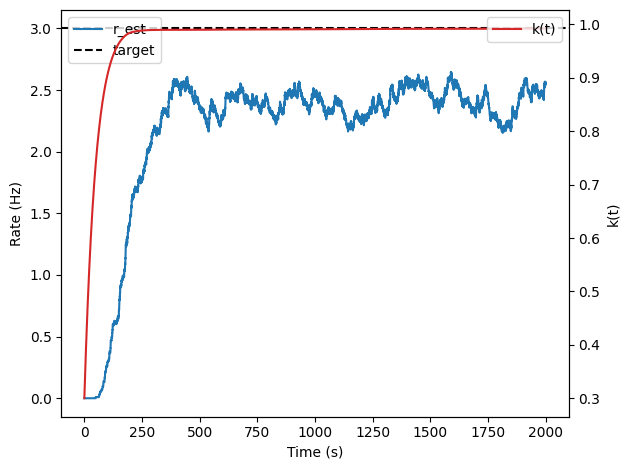

In [15]:
from brian2 import *

start_scope()
defaultclock.dt = 1*ms

V_L = -70*mV
V_thr = -50*mV
V_reset = -55*mV
V_E = 0*mV

C_m_E = 0.5*nF
g_m_E = 10*nS
tau_AMPA = 8*ms

tau_HSP = 100*second
target_rate = 3*Hz

tau_ins_AMPA_E = 50*second
tau_int_AMPA_E = 50*second

eqs_E = '''
dv/dt = (-g_m_E*(v - V_L) - I_syn)/C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext : amp

I_AMPA_ext = g_AMPA_ext_E * k_AMPA_E_hsp * (v - V_E) * s_AMPA_ext : amp

ds_AMPA_ext/dt = -s_AMPA_ext/tau_AMPA : 1

dx_spike/dt = -x_spike/tau_HSP : 1
r_est = x_spike/tau_HSP : Hz

# HSP scaling variables
dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
            - k_AMPA_E_hsp * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

'''

P = NeuronGroup(1, eqs_E,
                threshold='v > V_thr',
                reset='v = V_reset; x_spike += 1.',
                refractory=2*ms,
                method='euler')

P.v = V_L
P.k_AMPA_E_hsp = 0.3 

g_AMPA_ext_E = 5.5*nS

rate_in = 40*Hz  
inp = PoissonGroup(2, rates=rate_in)

S = Synapses(inp, P, model='w:1', on_pre='s_AMPA_ext += w')
S.connect()
S.w = 0.70

# Monitors
mon = StateMonitor(P, ['v', 'r_est', 'k_AMPA_E_hsp'], record=True, dt=100*ms)
sp = SpikeMonitor(P)

# Run long enough that HSP can act
run(2000*second, report='text')

# Quick plot
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()
ax1.plot(mon.t/second, mon.r_est[0]/Hz, label='r_est')
ax1.axhline(target_rate/Hz, color='k', linestyle='--', label='target')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Rate (Hz)')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(mon.t/second, mon.k_AMPA_E_hsp[0], color='tab:red', label='k(t)')
ax2.set_ylabel('k(t)')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()
